In [1]:
import os
import copy
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [5]:
from pathlib import Path

# Project root (since notebook is inside notebooks/)
PROJECT_ROOT = Path.cwd().parent

# Data folders
train_dir = PROJECT_ROOT / "data" / "balanced" / "train"
val_dir   = PROJECT_ROOT / "data" / "processed" / "val"
test_dir  = PROJECT_ROOT / "data" / "processed" / "test"

print("Train dir:", train_dir)
print("Val dir  :", val_dir)
print("Test dir :", test_dir)

print("\nExists check:")
print("Train exists:", train_dir.exists())
print("Val exists  :", val_dir.exists())
print("Test exists :", test_dir.exists())

Train dir: c:\Extra stuff\capstone\DeepfakeProject\DeepfakeProject\data\balanced\train
Val dir  : c:\Extra stuff\capstone\DeepfakeProject\DeepfakeProject\data\processed\val
Test dir : c:\Extra stuff\capstone\DeepfakeProject\DeepfakeProject\data\processed\test

Exists check:
Train exists: True
Val exists  : True
Test exists : True


In [6]:
classes = ["real", "deepfake", "edited", "ai_generated"]

def count_images_in_folder(folder_path, class_names):
    counts = {}
    for cls in class_names:
        class_path = folder_path / cls
        if class_path.exists():
            counts[cls] = len([
                f for f in class_path.iterdir()
                if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
            ])
        else:
            counts[cls] = 0
    return counts

train_counts = count_images_in_folder(train_dir, classes)
val_counts   = count_images_in_folder(val_dir, classes)
test_counts  = count_images_in_folder(test_dir, classes)

print("Train class counts:")
for k, v in train_counts.items():
    print(f"{k}: {v}")

print("\nValidation class counts:")
for k, v in val_counts.items():
    print(f"{k}: {v}")

print("\nTest class counts:")
for k, v in test_counts.items():
    print(f"{k}: {v}")

Train class counts:
real: 400
deepfake: 400
edited: 400
ai_generated: 400

Validation class counts:
real: 1522
deepfake: 1582
edited: 39
ai_generated: 25

Test class counts:
real: 1523
deepfake: 1582
edited: 39
ai_generated: 25


In [7]:
from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [8]:
from torchvision import datasets

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset   = datasets.ImageFolder(val_dir, transform=eval_transform)
test_dataset  = datasets.ImageFolder(test_dir, transform=eval_transform)

print("Class to index mapping:", train_dataset.class_to_idx)
print("Train samples:", len(train_dataset))
print("Val samples  :", len(val_dataset))
print("Test samples :", len(test_dataset))

Class to index mapping: {'ai_generated': 0, 'deepfake': 1, 'edited': 2, 'real': 3}
Train samples: 1600
Val samples  : 3168
Test samples : 3169


In [10]:
print(train_dataset.class_to_idx)

{'ai_generated': 0, 'deepfake': 1, 'edited': 2, 'real': 3}


In [9]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


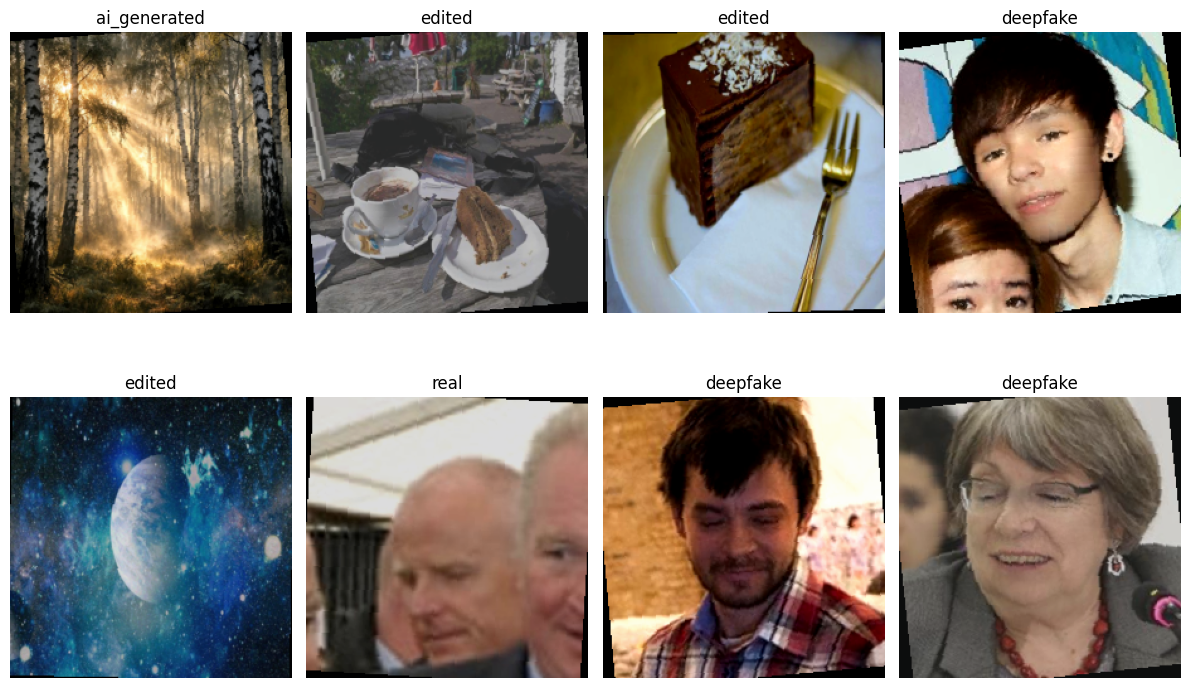

In [11]:
import matplotlib.pyplot as plt
import numpy as np

def imshow_tensor(img_tensor, title=None):
    img = img_tensor.cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)

    plt.imshow(img)
    if title:
        plt.title(title)
    plt.axis("off")

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    imshow_tensor(images[i], title=train_dataset.classes[labels[i]])
plt.tight_layout()
plt.show()

In [12]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Replace final classifier for 4 classes
in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(in_features, 4)
)

model = model.to(device)

print("Model moved to:", device)
print("Final classifier:", model.classifier)

Model moved to: cuda
Final classifier: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)


In [13]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        running_correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_correct = 0
    total = 0

    all_labels = []
    all_preds = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            running_correct += (preds == labels).sum().item()
            total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc, all_labels, all_preds

In [20]:
import copy

best_val_loss = float("inf")
EPOCHS = 10
best_val_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):
    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print("-" * 50)

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f}")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_val_loss = val_loss
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), "best_balanced_efficientnet_b0.pth")
        print("✅ Best model saved.")
    
print("\nTraining complete.")


Epoch [1/10]
--------------------------------------------------
Train Loss: 0.0154 | Train Acc: 0.9950
Val   Loss: 0.1177 | Val   Acc: 0.9612
✅ Best model saved.

Epoch [2/10]
--------------------------------------------------
Train Loss: 0.0175 | Train Acc: 0.9956
Val   Loss: 0.1140 | Val   Acc: 0.9621
✅ Best model saved.

Epoch [3/10]
--------------------------------------------------
Train Loss: 0.0125 | Train Acc: 0.9969
Val   Loss: 0.1156 | Val   Acc: 0.9618

Epoch [4/10]
--------------------------------------------------
Train Loss: 0.0152 | Train Acc: 0.9962
Val   Loss: 0.1146 | Val   Acc: 0.9618

Epoch [5/10]
--------------------------------------------------
Train Loss: 0.0097 | Train Acc: 0.9994
Val   Loss: 0.1133 | Val   Acc: 0.9612

Epoch [6/10]
--------------------------------------------------
Train Loss: 0.0071 | Train Acc: 0.9988
Val   Loss: 0.1121 | Val   Acc: 0.9615

Epoch [7/10]
--------------------------------------------------
Train Loss: 0.0075 | Train Acc: 0.998

In [21]:
model.load_state_dict(best_model_wts)

print("Best model weights loaded.")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Validation Loss at Best Accuracy: {best_val_loss:.4f}")

Best model weights loaded.
Best Validation Accuracy: 0.9628
Validation Loss at Best Accuracy: 0.1129


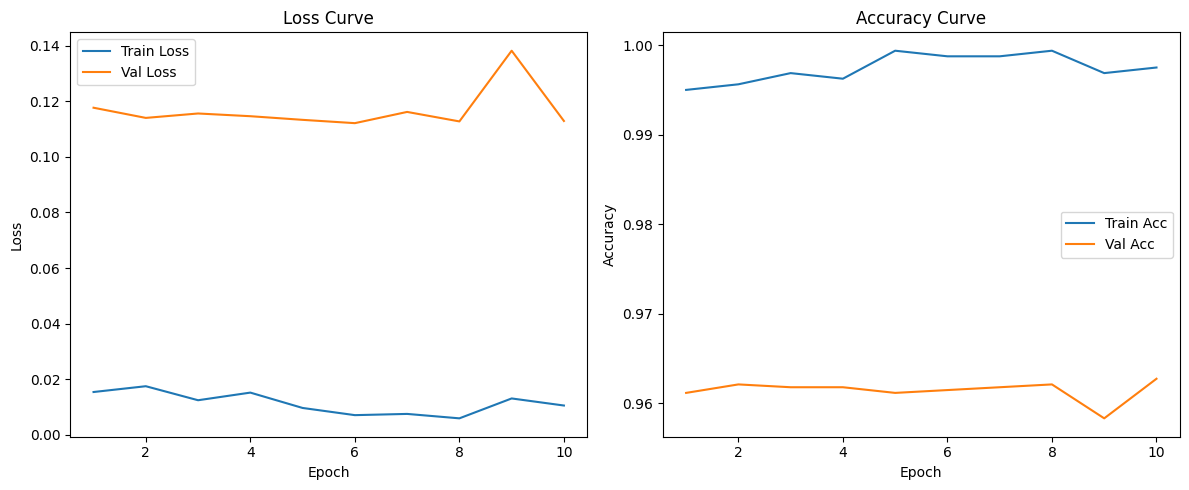

In [22]:
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss")
plt.plot(epochs_range, history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], label="Train Acc")
plt.plot(epochs_range, history["val_acc"], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()

plt.tight_layout()
plt.show()